# LAB 3 - Bài 2: Phân lớp MNIST bằng Neural Network
Hồng Kim Dung - 6451071009

## Câu a - Đọc bộ dữ liệu MNIST

In [1]:
print("Hồng Kim Dung - 6451071009")
from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc xong bộ dữ liệu MNIST")

Hồng Kim Dung - 6451071009
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Đã đọc xong bộ dữ liệu MNIST


## Câu b - Kích thước tập train, test

In [2]:
print("Hồng Kim Dung - 6451071009")
print("train_images:", train_images.shape, "| train_labels:", train_labels.shape)
print("test_images :", test_images.shape, "| test_labels :", test_labels.shape)

Hồng Kim Dung - 6451071009
train_images: (60000, 28, 28) | train_labels: (60000,)
test_images : (10000, 28, 28) | test_labels : (10000,)


## Câu c - Chuẩn hóa pixel về [0,1]

In [3]:
print("Hồng Kim Dung - 6451071009")
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Min:", train_images.min(), "| Max:", train_images.max())

Hồng Kim Dung - 6451071009
Min: 0.0 | Max: 1.0


## Câu d - Chia train / validation (8:2)

In [4]:
print("Hồng Kim Dung - 6451071009")
from sklearn.model_selection import train_test_split

train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42)

print("train     :", train_images.shape, train_labels.shape)
print("validation:", validation_images.shape, validation_labels.shape)

Hồng Kim Dung - 6451071009
train     : (48000, 28, 28) (48000,)
validation: (12000, 28, 28) (12000,)


## Câu e, f - Xây dựng và biên dịch mô hình

In [5]:
print("Hồng Kim Dung - 6451071009")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Hồng Kim Dung - 6451071009


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Câu g - Huấn luyện mô hình

In [6]:
print("Hồng Kim Dung - 6451071009")
history = model.fit(train_images, train_labels,
                    validation_data=(validation_images, validation_labels),
                    epochs=5, batch_size=32, verbose=1)

Hồng Kim Dung - 6451071009
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9070 - loss: 0.3169 - val_accuracy: 0.9553 - val_loss: 0.1549
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9557 - loss: 0.1521 - val_accuracy: 0.9664 - val_loss: 0.1125
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9657 - loss: 0.1122 - val_accuracy: 0.9706 - val_loss: 0.0982
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9704 - loss: 0.0953 - val_accuracy: 0.9727 - val_loss: 0.0887
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9741 - loss: 0.0819 - val_accuracy: 0.9753 - val_loss: 0.0802


## Câu h - Biểu đồ accuracy, loss

Hồng Kim Dung - 6451071009


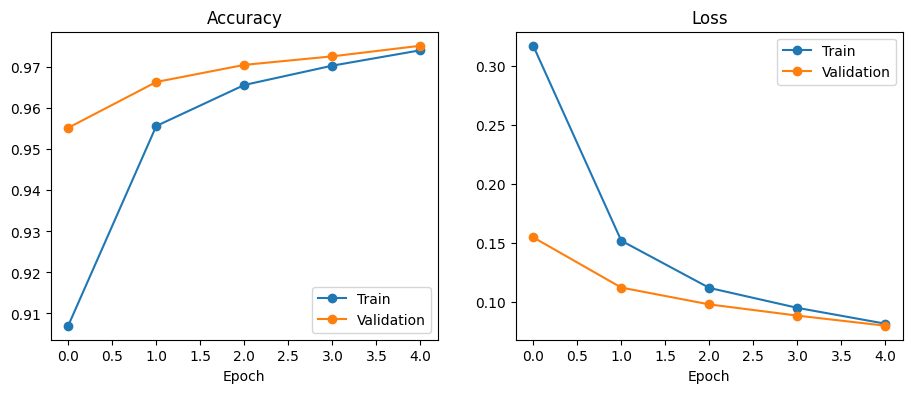

In [7]:
print("Hồng Kim Dung - 6451071009")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], marker="o", label="Train")
ax[0].plot(history.history["val_accuracy"], marker="o", label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history.history["loss"], marker="o", label="Train")
ax[1].plot(history.history["val_loss"], marker="o", label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

## Câu i, j - Dự đoán tập test và Accuracy

In [8]:
print("Hồng Kim Dung - 6451071009")
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_prob = model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", accuracy_score(test_labels, y_pred))

Hồng Kim Dung - 6451071009
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy: 0.9746


## Câu k - Precision, Recall, F1-score

In [9]:
print("Hồng Kim Dung - 6451071009")
print(classification_report(test_labels, y_pred, digits=4))

Hồng Kim Dung - 6451071009
              precision    recall  f1-score   support

           0     0.9867    0.9857    0.9862       980
           1     0.9877    0.9885    0.9881      1135
           2     0.9657    0.9826    0.9741      1032
           3     0.9545    0.9772    0.9658      1010
           4     0.9864    0.9613    0.9737       982
           5     0.9816    0.9585    0.9699       892
           6     0.9812    0.9802    0.9807       958
           7     0.9719    0.9757    0.9738      1028
           8     0.9699    0.9589    0.9644       974
           9     0.9618    0.9732    0.9675      1009

    accuracy                         0.9746     10000
   macro avg     0.9747    0.9742    0.9744     10000
weighted avg     0.9747    0.9746    0.9746     10000



## Câu l - Confusion matrix (heat map)

Hồng Kim Dung - 6451071009


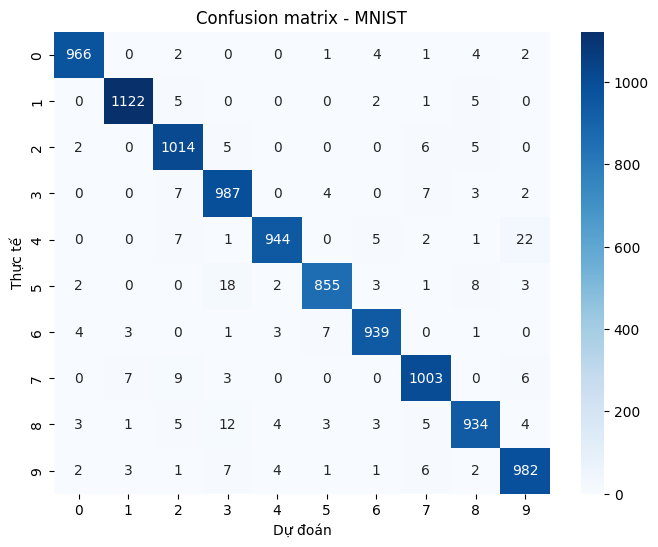

In [10]:
print("Hồng Kim Dung - 6451071009")
import seaborn as sns

cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Confusion matrix - MNIST")
plt.show()

## Câu m - Phân lớp 5 ảnh đầu tiên của tập test

Hồng Kim Dung - 6451071009
Ảnh 0: dự đoán = 7, thực tế = 7
Ảnh 1: dự đoán = 2, thực tế = 2
Ảnh 2: dự đoán = 1, thực tế = 1
Ảnh 3: dự đoán = 0, thực tế = 0
Ảnh 4: dự đoán = 4, thực tế = 4


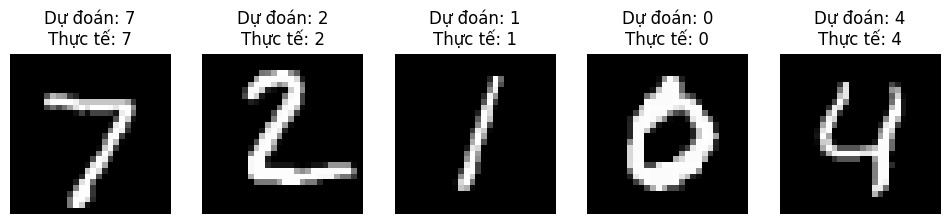

In [11]:
print("Hồng Kim Dung - 6451071009")
plt.figure(figsize=(12, 3))
for i in range(5):
    img = np.expand_dims(test_images[i], axis=0)       # (1, 28, 28)
    pred = np.argmax(model.predict(img, verbose=0), axis=1)[0]
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_images[i], cmap="gray")
    plt.title(f"Dự đoán: {pred}\nThực tế: {test_labels[i]}")
    plt.axis("off")
    print(f"Ảnh {i}: dự đoán = {pred}, thực tế = {test_labels[i]}")
plt.show()

## Câu n - 5 ảnh đầu tiên bị phân lớp sai

Hồng Kim Dung - 6451071009
Ảnh #151: dự đoán = 8, thực tế = 9
Ảnh #247: dự đoán = 2, thực tế = 4
Ảnh #274: dự đoán = 3, thực tế = 9
Ảnh #321: dự đoán = 7, thực tế = 2
Ảnh #340: dự đoán = 3, thực tế = 5


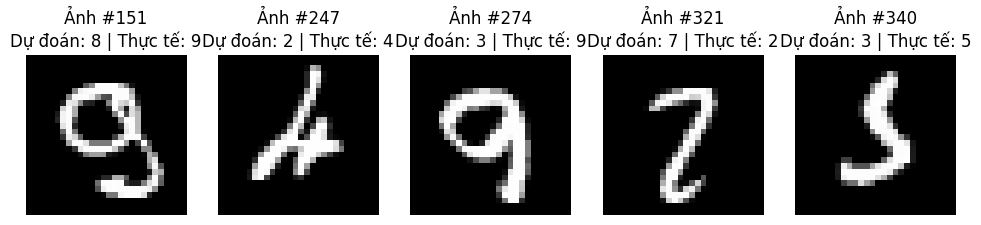

In [12]:
print("Hồng Kim Dung - 6451071009")
sai = np.where(y_pred != test_labels)[0][:5]    # chỉ số 5 mẫu sai đầu tiên

plt.figure(figsize=(12, 3))
for k, idx in enumerate(sai):
    plt.subplot(1, 5, k + 1)
    plt.imshow(test_images[idx], cmap="gray")
    plt.title(f"Ảnh #{idx}\nDự đoán: {y_pred[idx]} | Thực tế: {test_labels[idx]}")
    plt.axis("off")
    print(f"Ảnh #{idx}: dự đoán = {y_pred[idx]}, thực tế = {test_labels[idx]}")
plt.show()